# 02 Data Preprocessing & Feature Scaling
**Project Title**: Intelligent Cloud Server Anomaly Detection and Real-Time Monitoring System

In this notebook, we load our validated historical server metrics and scale them using **MinMaxScaler** (0 to 1 normalization). Scaling is a mandatory preprocessing step for distance-based and clustering algorithms such as DBSCAN and LOF, as unscaled columns with large absolute values (e.g. response time in ms) would dominate distance calculations relative to columns with small ranges (e.g. network traffic).

In [3]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path

# Add python directory to path so we can import our processor
sys.path.append("../")
from python.data_processor import DataProcessor

sns.set_theme(style="whitegrid")

# Load validated metrics
data_path = "../data/processed/validated_historical_metrics.csv"
df = pd.read_csv(data_path)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df.head()

,timestamp,server_id,cpu_usage,memory_usage,disk_usage,network_traffic,response_time,request_rate
0,2014-02-14 14:27:00,SERVER-01,51.846,63.433712,0.1,0.239985,72.239873,96.050844
1,2014-02-14 14:32:00,SERVER-01,44.508,60.856538,0.1,3.055105,62.801950,85.923800
2,2014-02-14 14:37:00,SERVER-01,41.244,59.360727,0.1,0.274083,62.723795,79.731062
3,2014-02-14 14:42:00,SERVER-01,48.568,62.804124,0.1,0.227875,54.152422,81.115477
4,2014-02-14 14:47:00,SERVER-01,46.714,60.620752,0.1,0.234489,61.861019,84.759392


## 1. MinMax Scaling Transformation
We instantiate our `DataProcessor` class, which fits a `MinMaxScaler` on the metrics and saves it as `models/scaler.joblib`.

In [ ]:
processor = DataProcessor(scaler_path="../models/scaler.joblib")
df_scaled = processor.fit_transform(df)
df_scaled.head()

## 2. Inspecting Scaled Stats
Let's check the minimum and maximum values of the scaled columns to verify they reside strictly within $[0, 1]$.

In [ ]:
scaled_cols = [col for col in df_scaled.columns if col.startswith("scaled_")]
df_scaled[scaled_cols].describe().T

## 3. Visualizing Before and After Scaling
We plot the CPU and Response Time metrics before and after MinMax scaling to visually demonstrate that the distribution shapes remain identical while the numerical ranges are normalized.

NameError: name 'df_scaled' is not defined

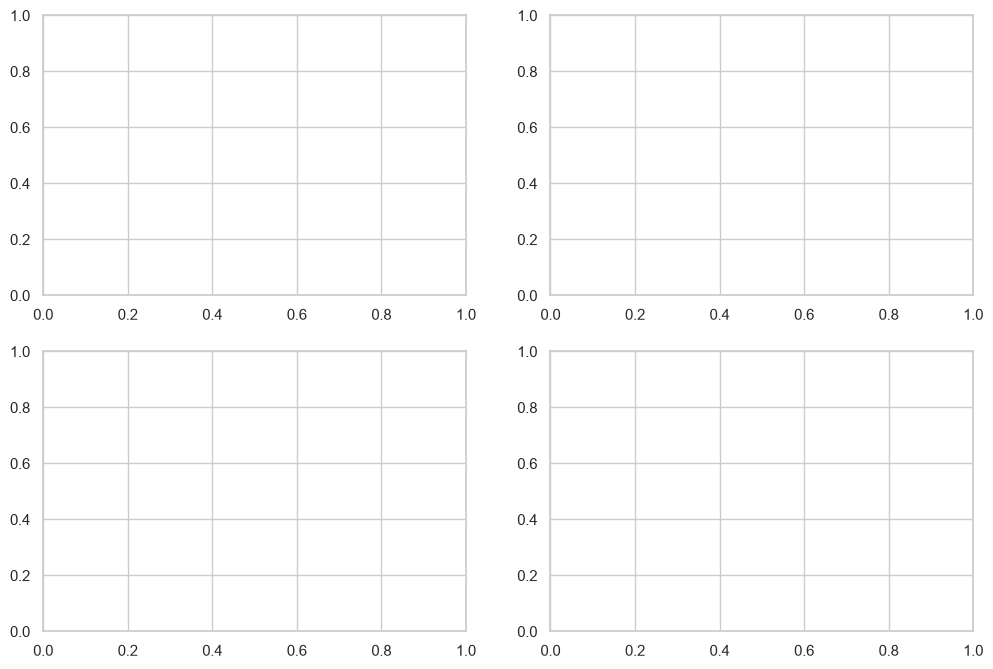

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# CPU Usage Raw
sns.histplot(df_scaled["cpu_usage"], ax=axes[0, 0], color="blue", kde=True, alpha=0.6)
axes[0, 0].set_title("CPU Usage (Raw %)")

# CPU Usage Scaled
sns.histplot(df_scaled["scaled_cpu_usage"], ax=axes[0, 1], color="darkblue", kde=True, alpha=0.6)
axes[0, 1].set_title("CPU Usage (MinMax Scaled)")

# Response Time Raw
sns.histplot(df_scaled["response_time"], ax=axes[1, 0], color="purple", kde=True, alpha=0.6)
axes[1, 0].set_title("Response Time (Raw ms)")

# Response Time Scaled
sns.histplot(df_scaled["scaled_response_time"], ax=axes[1, 1], color="indigo", kde=True, alpha=0.6)
axes[1, 1].set_title("Response Time (MinMax Scaled)")

plt.tight_layout()
plt.show()

## 4. Verification of Scaler Persistence
We test loading the saved scaler from `models/scaler.joblib` and applying it to transform an ad-hoc test sample, simulating the real-time pipeline behavior.

In [5]:
test_record = pd.DataFrame([{
    "cpu_usage": 85.0,
    "memory_usage": 78.0,
    "disk_usage": 45.0,
    "network_traffic": 120.0,
    "response_time": 450.0,
    "request_rate": 200.0
}])

loaded_scaler = joblib.load("../models/scaler.joblib")
scaled_test = loaded_scaler.transform(test_record)
print("Raw input:\n", test_record)
print("\nScaled output:\n", scaled_test)

Raw input:
    cpu_usage  memory_usage  disk_usage  network_traffic  response_time  \
0       85.0          78.0        45.0            120.0          450.0   

   request_rate  
0         200.0  

Scaled output:
 [[0.84845494 0.78313257 0.08981796 0.51311598 2.16020722 0.30381679]]
